# Customer Segmentation – EDA & Preprocessing
Data ingestion, cleaning and exploratory data analysis


In [105]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer  
from sklearn.impute import IterativeImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer

from sklearn import set_config

sns.set_theme(style='whitegrid', palette='tab10')
%matplotlib inline
print('Libraries loaded.')

Libraries loaded.


## 1 · Load & Inspect Raw Data

In [106]:
# Load the raw data
RAW_PATH = '../data/raw/customer_segmentation.csv'
df_raw = pd.read_csv(RAW_PATH)
print(f'Shape: {df_raw.shape}')
df_raw.head()

Shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


#### Initial data inspection

In [107]:
# check for Data types and feature name inconsistencies
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

Dt_Customer need to convert to date column, all data types are seems to be ok

In [108]:
# convert Dt_Customer to date type
df_raw["Dt_Customer"] = pd.to_datetime(df_raw["Dt_Customer"], format="%d-%m-%Y", errors="coerce")
#df_raw.info()

In [109]:
# check unique values in categorical features
df_raw['Education'].unique(),df_raw['Marital_Status'].unique()

(<StringArray>
 ['Graduation', 'PhD', 'Master', 'Basic', '2n Cycle']
 Length: 5, dtype: str,
 <StringArray>
 ['Single', 'Together', 'Married', 'Divorced', 'Widow', 'Alone', 'Absurd',
  'YOLO']
 Length: 8, dtype: str)

In [110]:
# grabs categorical features to a list
cat_cols = df_raw.select_dtypes(include=["string", "object"]).columns.tolist()
cat_cols

['Education', 'Marital_Status']

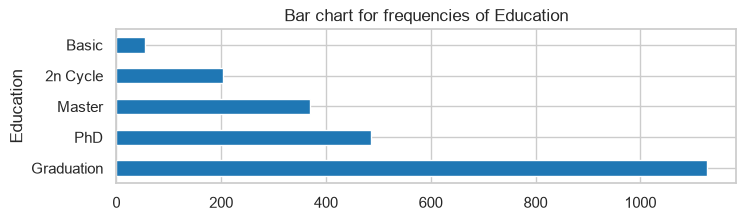

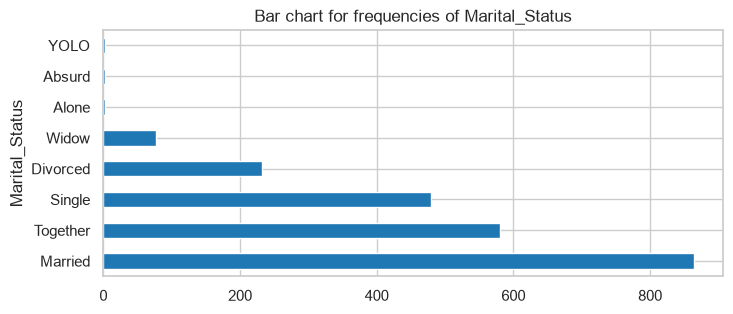

In [111]:
# bar char for categorical features
for col in cat_cols:
    freq_table = df_raw[col].value_counts()
    plt.figure(figsize = (8,len(freq_table)*0.4)) #a bit formatting so that chart look better
    freq_table.plot.barh(title='Bar chart for frequencies of ' + col)
    plt.show()
    print()

need mapping for categorical features

<function matplotlib.pyplot.show(close=None, block=None)>

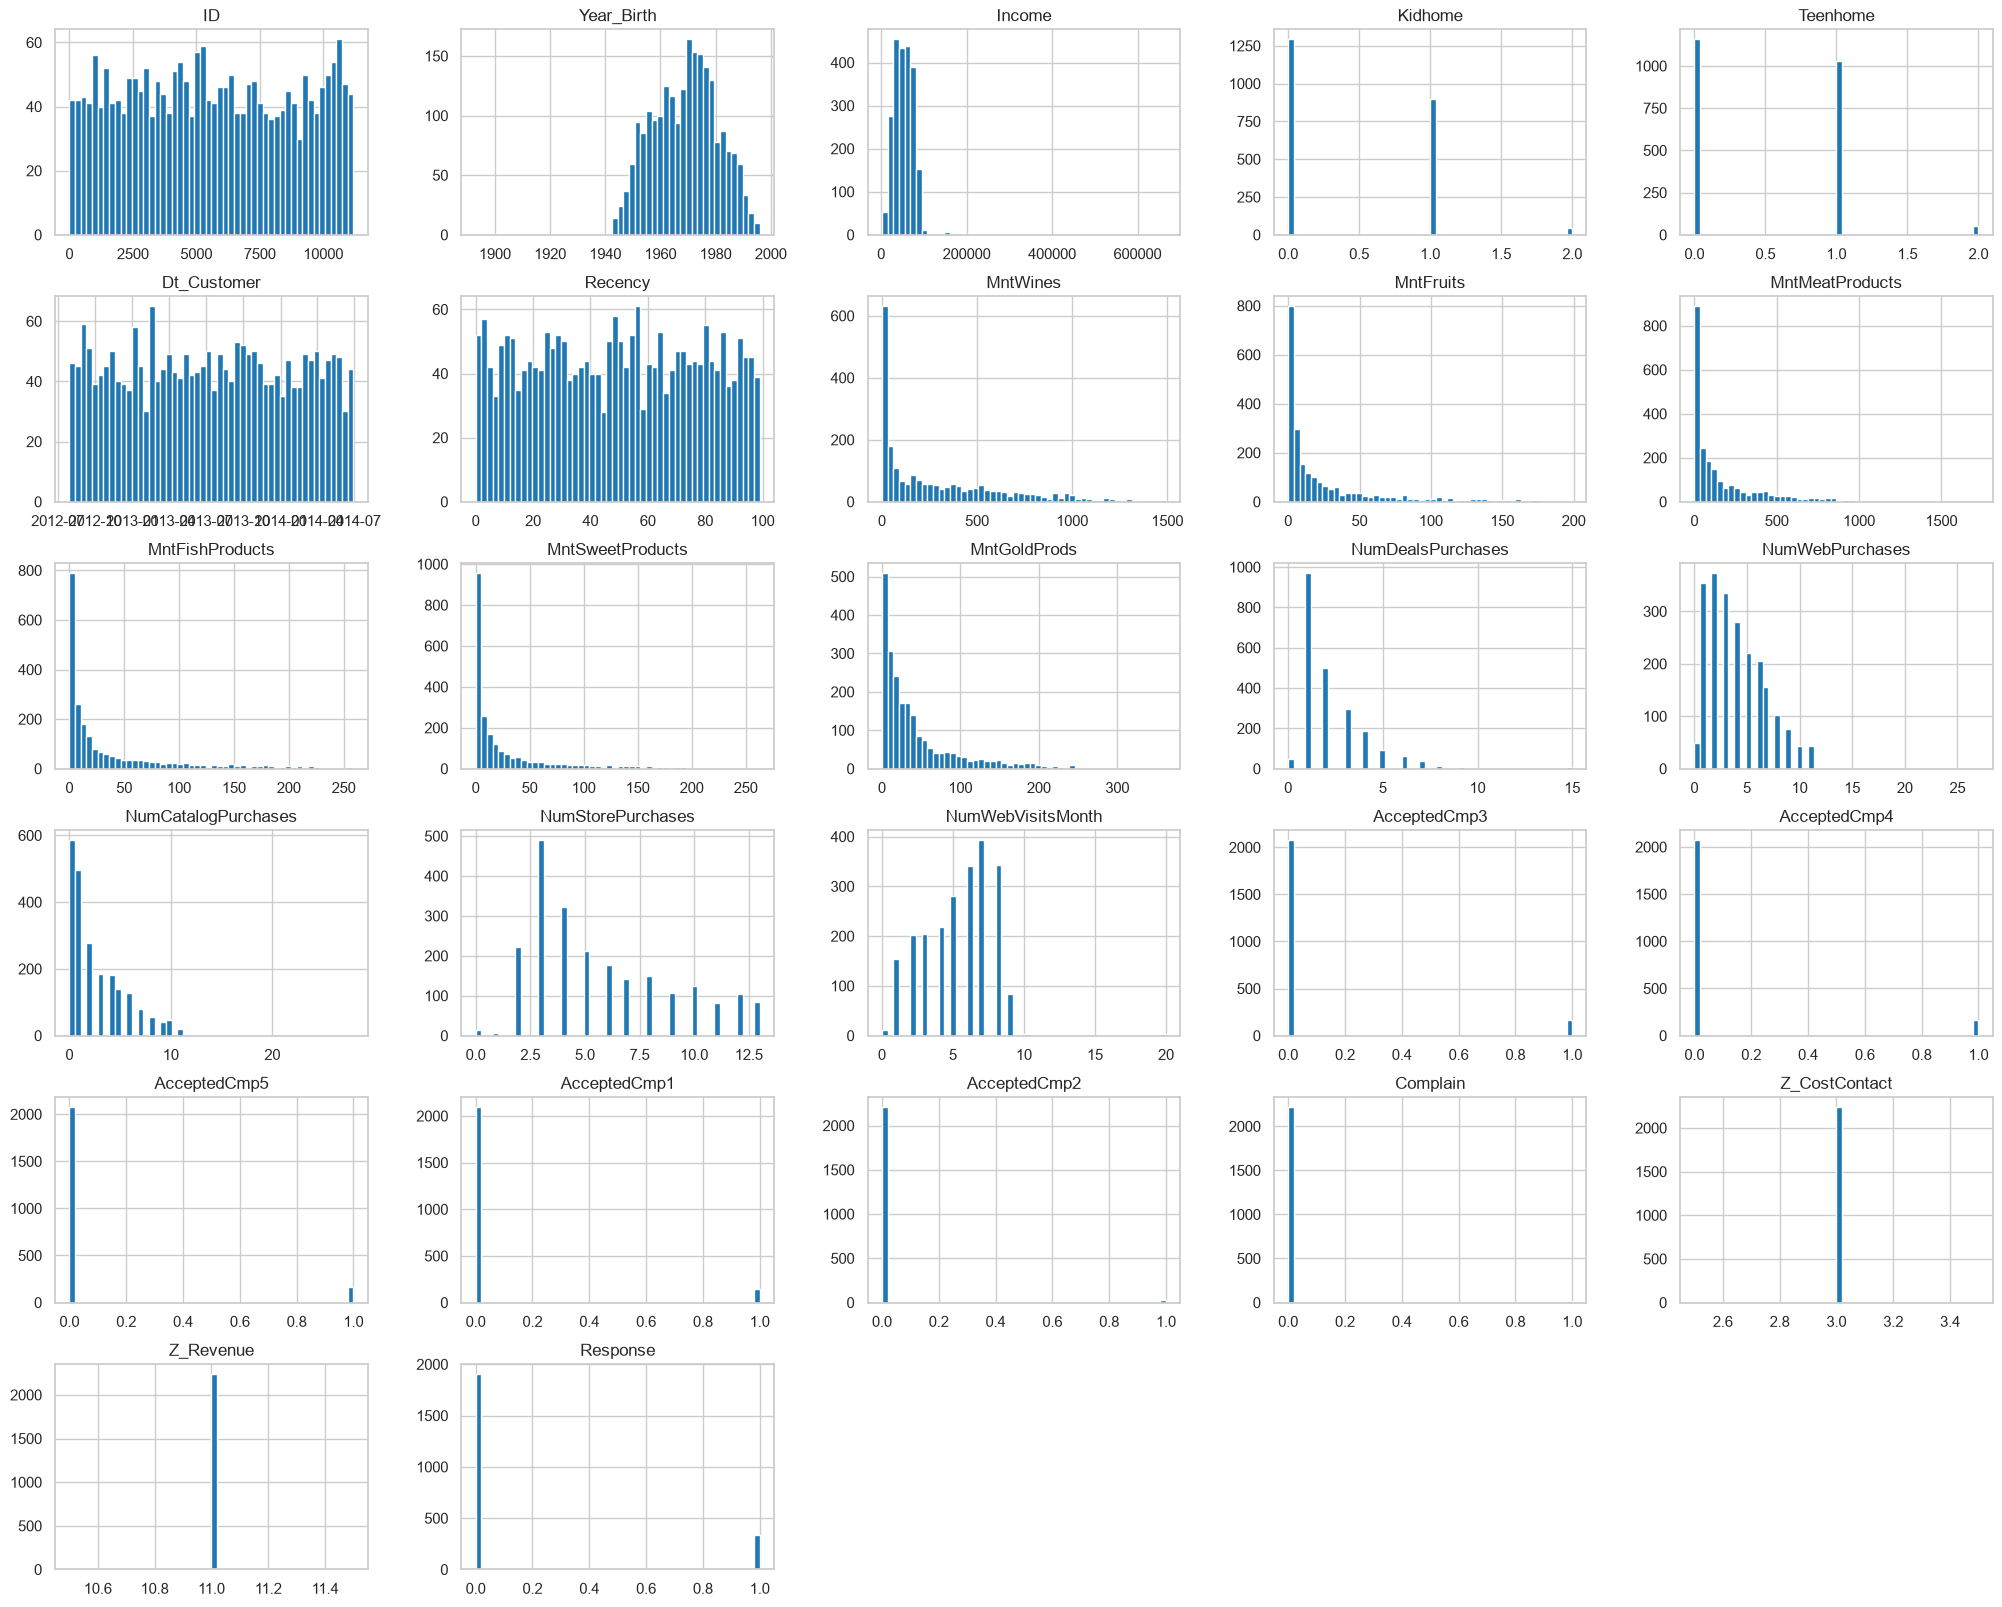

In [112]:
# histogram for numerical features
df_raw.hist(bins=50,figsize=(25,20))
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

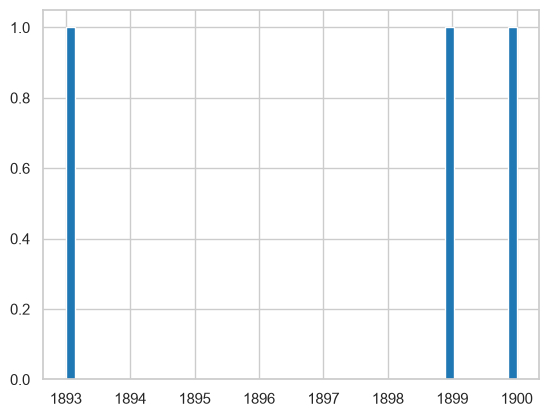

In [113]:
# check for outliers in Year_Birth
plt.hist(df_raw['Year_Birth'][df_raw['Year_Birth']<1940],bins=50)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

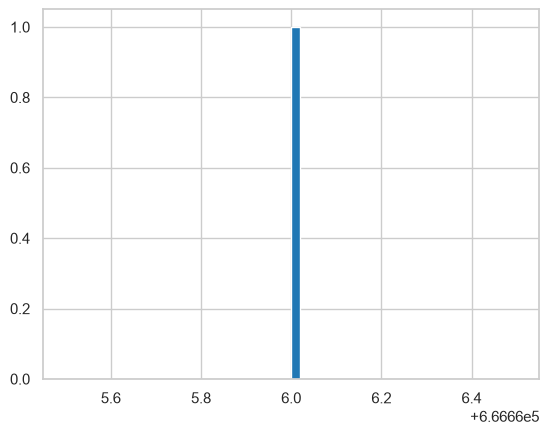

In [114]:
# check for outliers in Income
plt.hist(df_raw['Income'][df_raw['Income']>180000],bins=50)
plt.show

In [115]:
# Grab all numeric columns 
num_cols = df_raw.select_dtypes(include=['number']).columns.tolist()
num_cols

['ID',
 'Year_Birth',
 'Income',
 'Kidhome',
 'Teenhome',
 'Recency',
 'MntWines',
 'MntFruits',
 'MntMeatProducts',
 'MntFishProducts',
 'MntSweetProducts',
 'MntGoldProds',
 'NumDealsPurchases',
 'NumWebPurchases',
 'NumCatalogPurchases',
 'NumStorePurchases',
 'NumWebVisitsMonth',
 'AcceptedCmp3',
 'AcceptedCmp4',
 'AcceptedCmp5',
 'AcceptedCmp1',
 'AcceptedCmp2',
 'Complain',
 'Z_CostContact',
 'Z_Revenue',
 'Response']

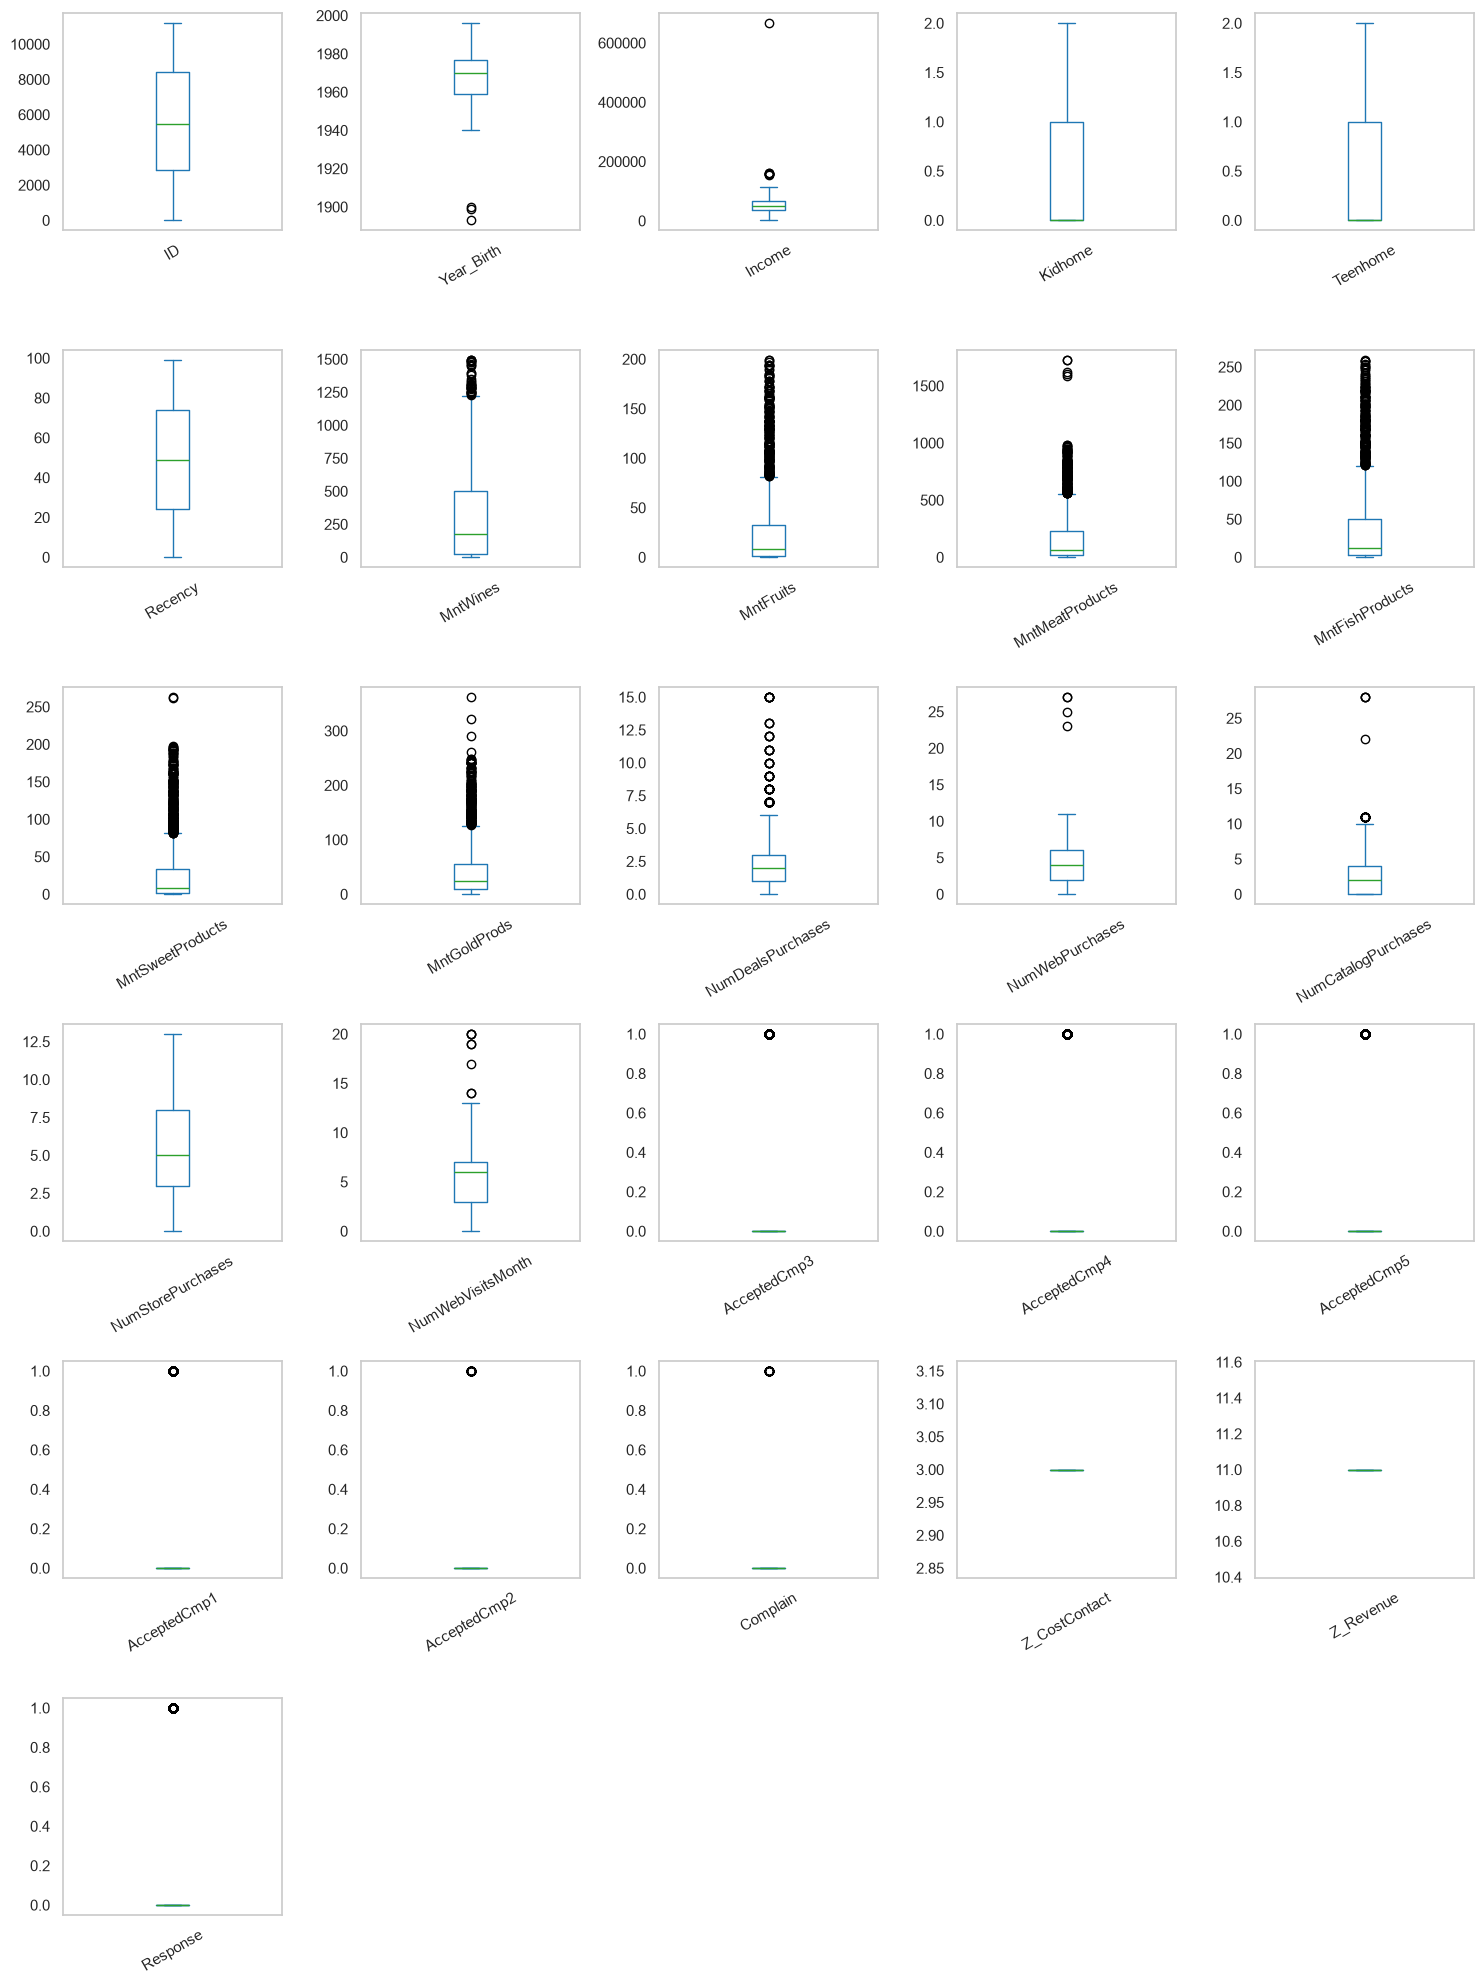

In [116]:
# Generates boxplots for numerical features
df_raw[num_cols].plot(
    kind='box', 
    subplots=True, 
    layout=(6, 5),      
    sharex=False, 
    sharey=False,       
    grid=False, 
    figsize=(15, 20), 
    rot=30
)
import matplotlib.pyplot as plt
plt.tight_layout()     # Prevents labels from overlapping
plt.show()


seems to have outliers to address in 'Year_Birth' and 'Income'

## 2 · Preprocess & Feature Engineering

#### Cheching for missing

In [117]:
# extract IDs into a separate container
customer_ids = df_raw["ID"].copy()
# Create a deep copy for EDA and modifications
df = df_raw.drop(columns=["ID"]).copy()
#df_raw.isnull().sum()
# check for missing values
pd.concat([df.isnull().sum(), df.isnull().mean()*100], axis=1, keys=['Missing Count', 'Percentage (%)'])

,Missing Count,Percentage (%)
Year_Birth,0,0.000000
Education,0,0.000000
Marital_Status,0,0.000000
Income,24,1.071429
Kidhome,0,0.000000
Teenhome,0,0.000000
Dt_Customer,0,0.000000
Recency,0,0.000000
MntWines,0,0.000000
MntFruits,0,0.000000


24 income data missing, can be imputed.

#### Cleaning

##### categorical features mapping & encoding

In [118]:
# categorical features mapping
EDUCATION_MAP = {"2n Cycle": "Master", "Basic": "High School", "Graduation": "Bachelor"}

MARITAL_MAP = {
    "Absurd": "Single", "Alone": "Single", "Divorced": "Single",
    "Together": "Married", "Widow": "Single", "YOLO": "Single",
}

df["Education"]     = df["Education"].replace(EDUCATION_MAP)
df["Marital_Status"] = df["Marital_Status"].replace(MARITAL_MAP)

# check unique values in categorical features
df['Education'].unique(),df['Marital_Status'].unique()

(<StringArray>
 ['Bachelor', 'PhD', 'Master', 'High School']
 Length: 4, dtype: str,
 <StringArray>
 ['Single', 'Married']
 Length: 2, dtype: str)

In [119]:
# Ordinal encoding
EDUCATION_ORDER = ["High School", "Bachelor", "Master", "PhD"]

MARITAL_ORDER   = ["Single", "Married"]

df["Education"] = (
    pd.Categorical(df["Education"], categories=EDUCATION_ORDER, ordered=True)
    .codes + 1
)
df["Marital_Status"] = (
    pd.Categorical(df["Marital_Status"], categories=MARITAL_ORDER, ordered=True)
    .codes + 1
)

In [120]:
# check unique values in categorical features after encoding
df['Education'].unique(),df['Marital_Status'].unique()

(array([2, 4, 3, 1], dtype=int8), array([1, 2], dtype=int8))

##### Mice imputation

Since only 1% income are missing, can be imputed

In [121]:
# Separate the datetime column
datetime_col = df['Dt_Customer'] # Replace with your actual column name
df_impute = df.drop(columns=['Dt_Customer'])

# Run the MICE imputation on numerical columns only
imputer = IterativeImputer(random_state=99)
imputed_array = imputer.fit_transform(df_impute)

# Rebuild the DataFrame and bring the datetime column back
df = pd.DataFrame(imputed_array, columns=df_impute.columns, index=df.index)
df['Dt_Customer'] = datetime_col



In [122]:
# check for missing values after imputation
print(f'Shape: {df.shape}')
df.isnull().sum()

Shape: (2240, 28)


Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
Z_CostContact          0
Z_Revenue              0
Response               0
Dt_Customer            0
dtype: int64

#### Feature Engeneering

In [123]:
REFERENCE_YEAR = 2021 # take reference year as 2021 to calculate age and tenure

df["amountSpent"] = (
        df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"]
        + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]
    )
df["numPurchases"] = (
    df["NumDealsPurchases"] + df["NumWebPurchases"]
    + df["NumCatalogPurchases"] + df["NumStorePurchases"]
)

df["Age"]      = REFERENCE_YEAR - df["Year_Birth"]
df["children"] = df["Kidhome"] + df["Teenhome"]
df["familySize"] = df["children"] + df["Marital_Status"]
df["tenure_ytd"] = REFERENCE_YEAR - df["Dt_Customer"].dt.year

cmp_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]
df["AcceptedCmp"] = (df[cmp_cols].sum(axis=1)) #  > 0).astype(int
df["is_AcceptedCmp"] = (df[cmp_cols].sum(axis=1)> 0).astype(int) #  

df["is_parent"] = (df["children"]> 0).astype(int) #  


In [124]:
# check the first few rows of the modified DataFrame
df.head()

,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,...,Dt_Customer,amountSpent,numPurchases,Age,children,familySize,tenure_ytd,AcceptedCmp,is_AcceptedCmp,is_parent
0,1957.0,2.0,1.0,58138.0,0.0,0.0,58.0,635.0,88.0,546.0,...,2012-09-04,1617.0,25.0,64.0,0.0,1.0,9,0.0,0,0
1,1954.0,2.0,1.0,46344.0,1.0,1.0,38.0,11.0,1.0,6.0,...,2014-03-08,27.0,6.0,67.0,2.0,3.0,7,0.0,0,1
2,1965.0,2.0,2.0,71613.0,0.0,0.0,26.0,426.0,49.0,127.0,...,2013-08-21,776.0,21.0,56.0,0.0,2.0,8,0.0,0,0
3,1984.0,2.0,2.0,26646.0,1.0,0.0,26.0,11.0,4.0,20.0,...,2014-02-10,53.0,8.0,37.0,1.0,3.0,7,0.0,0,1
4,1981.0,4.0,2.0,58293.0,1.0,0.0,94.0,173.0,43.0,118.0,...,2014-01-19,422.0,19.0,40.0,1.0,3.0,7,0.0,0,1


<function matplotlib.pyplot.show(close=None, block=None)>

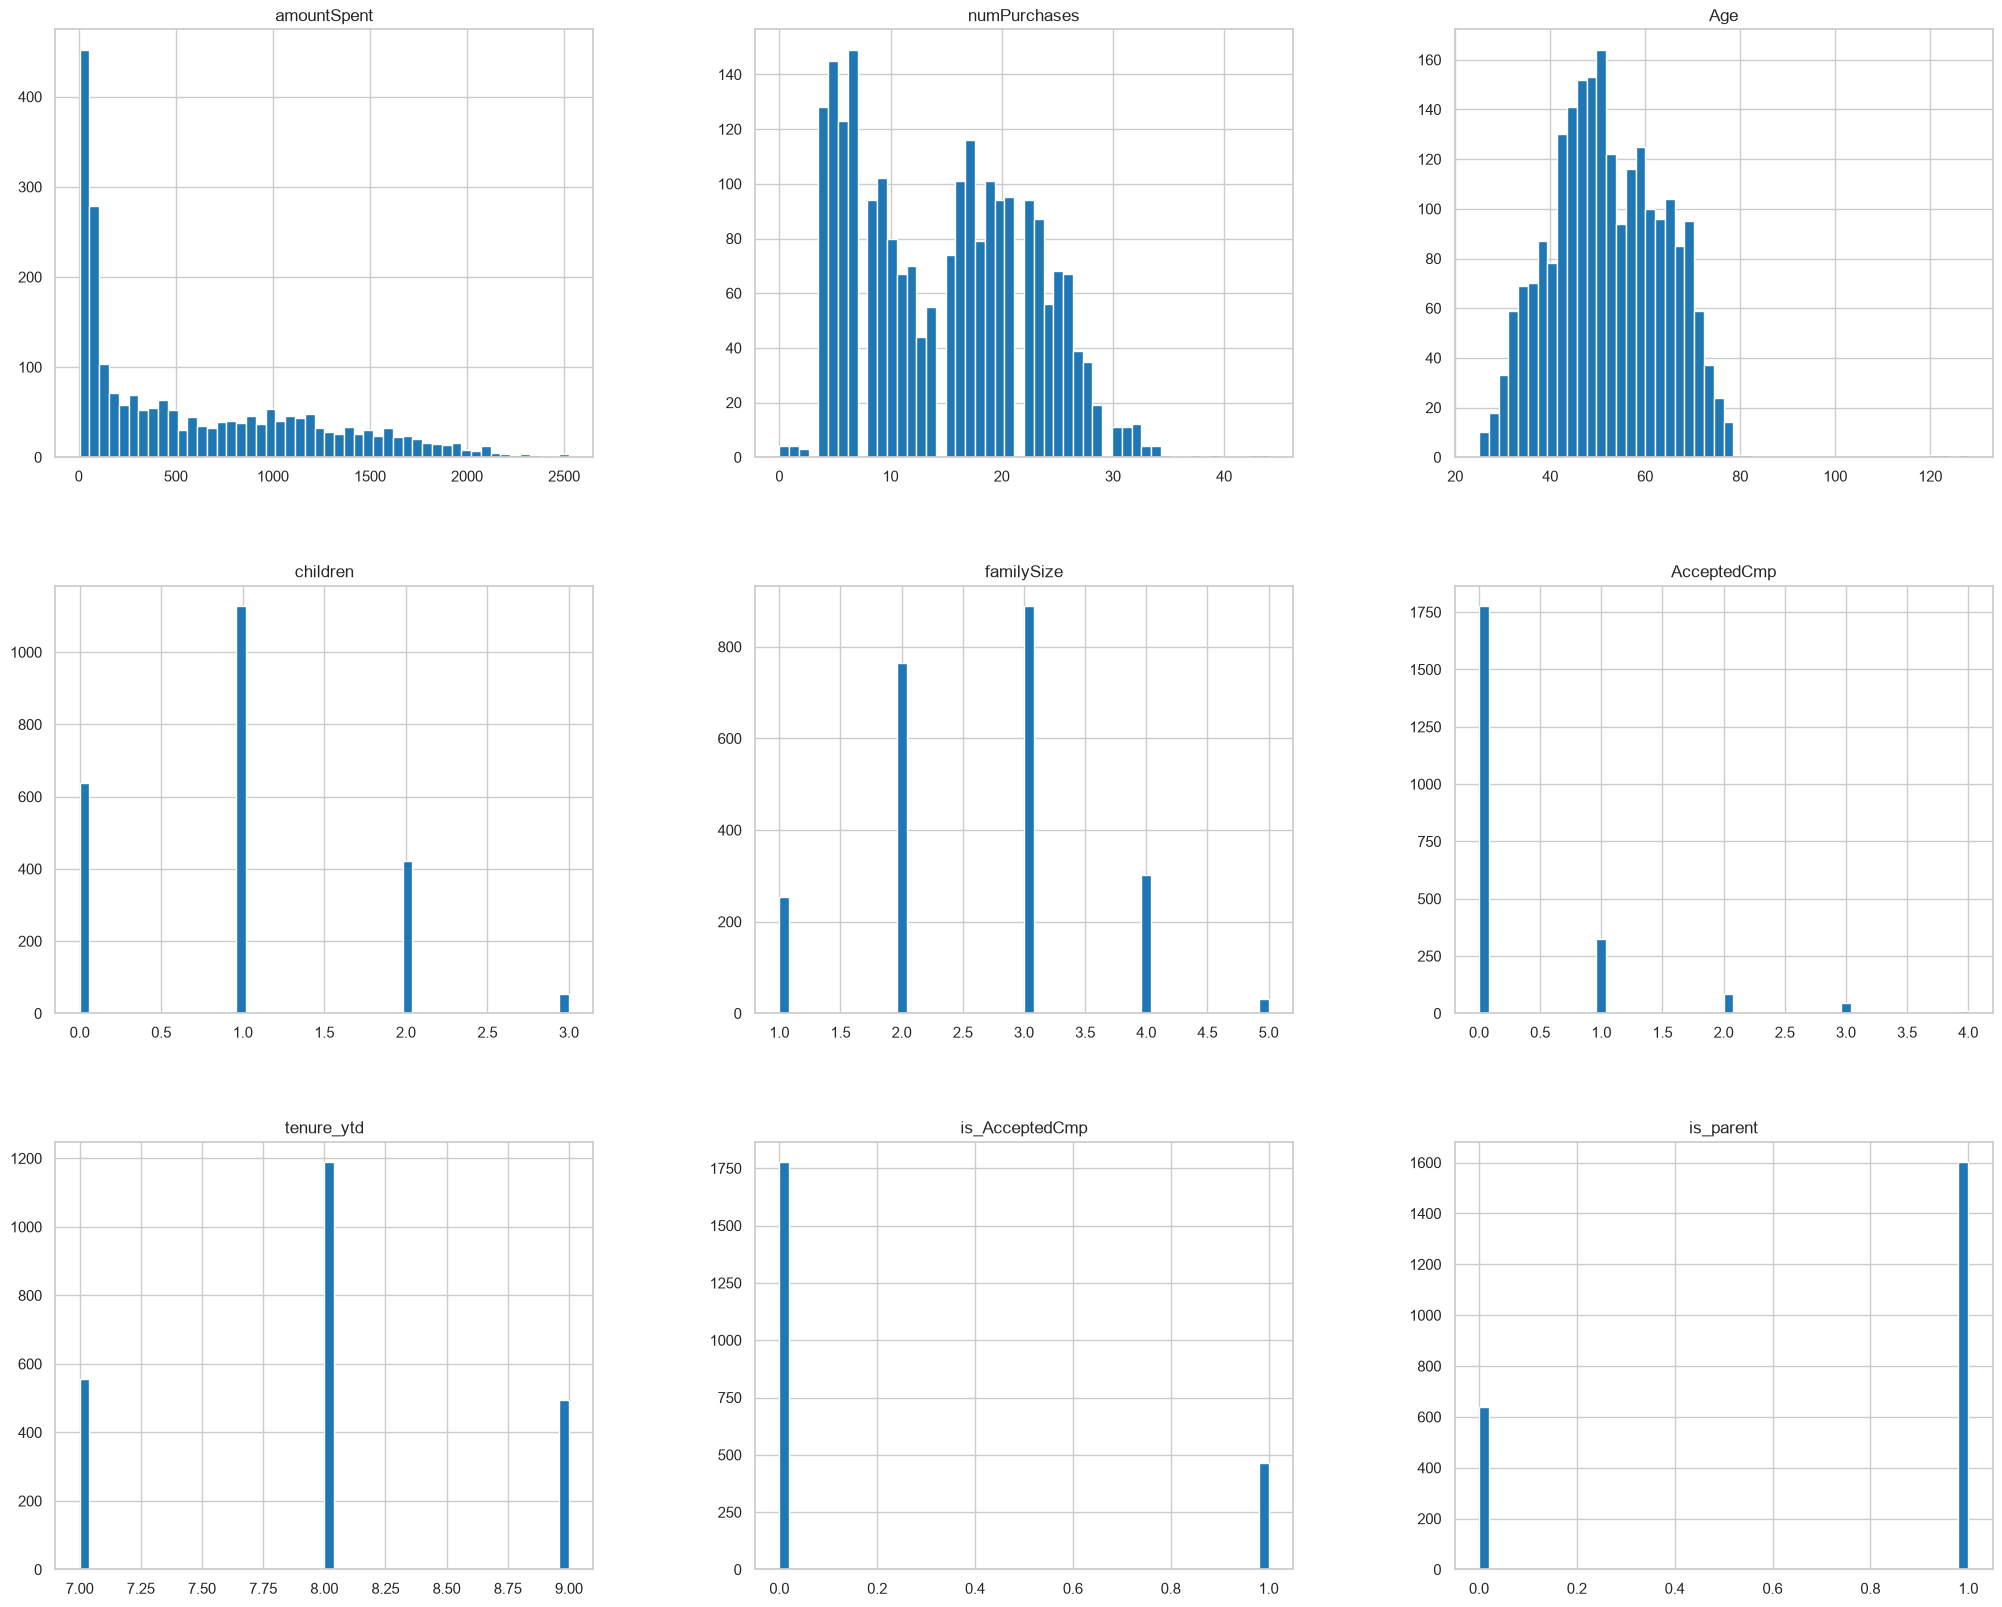

In [125]:
# histogram for engeered features
df[["amountSpent", "numPurchases", "Age", "children", "familySize", 
    "AcceptedCmp", "tenure_ytd", "is_AcceptedCmp", "is_parent"]].hist(bins=50,figsize=(25,20))
plt.show


#### Remove Outliers

In [126]:
BIRTH_YEAR_MAX    = 1940 # Maximum birth year
AGE_MAX    = 90 # Maximum age
INCOME_MAX = 200000 # Maximum income

# Filter the DataFrame based on the maximum values
before = len(df)
df = df[(df["Age"] < AGE_MAX) & (df["Income"] < INCOME_MAX)].copy()
print(before, before - len(df))
print(f'Shape: {df.shape}')

2240 4
Shape: (2236, 37)


In [127]:
# making a copy of the DataFrame for interim analysis and adding back the customer IDs

df_interim = df.copy()
df_interim.insert(0, "ID", customer_ids.loc[df.index].to_numpy())
df_interim.head()


# save the interim DataFrame to a CSV file
INTERIM_PATH = '../data/interim/customer_segmentation_interim.csv'
os.makedirs(os.path.dirname(INTERIM_PATH), exist_ok=True)
df_interim.to_csv(INTERIM_PATH, index=False)

print(f"Interim dataset saved with {df_interim.shape[1]} columns.")

Interim dataset saved with 38 columns.


## 3 · Exploratory Data Analysis

<function matplotlib.pyplot.show(close=None, block=None)>

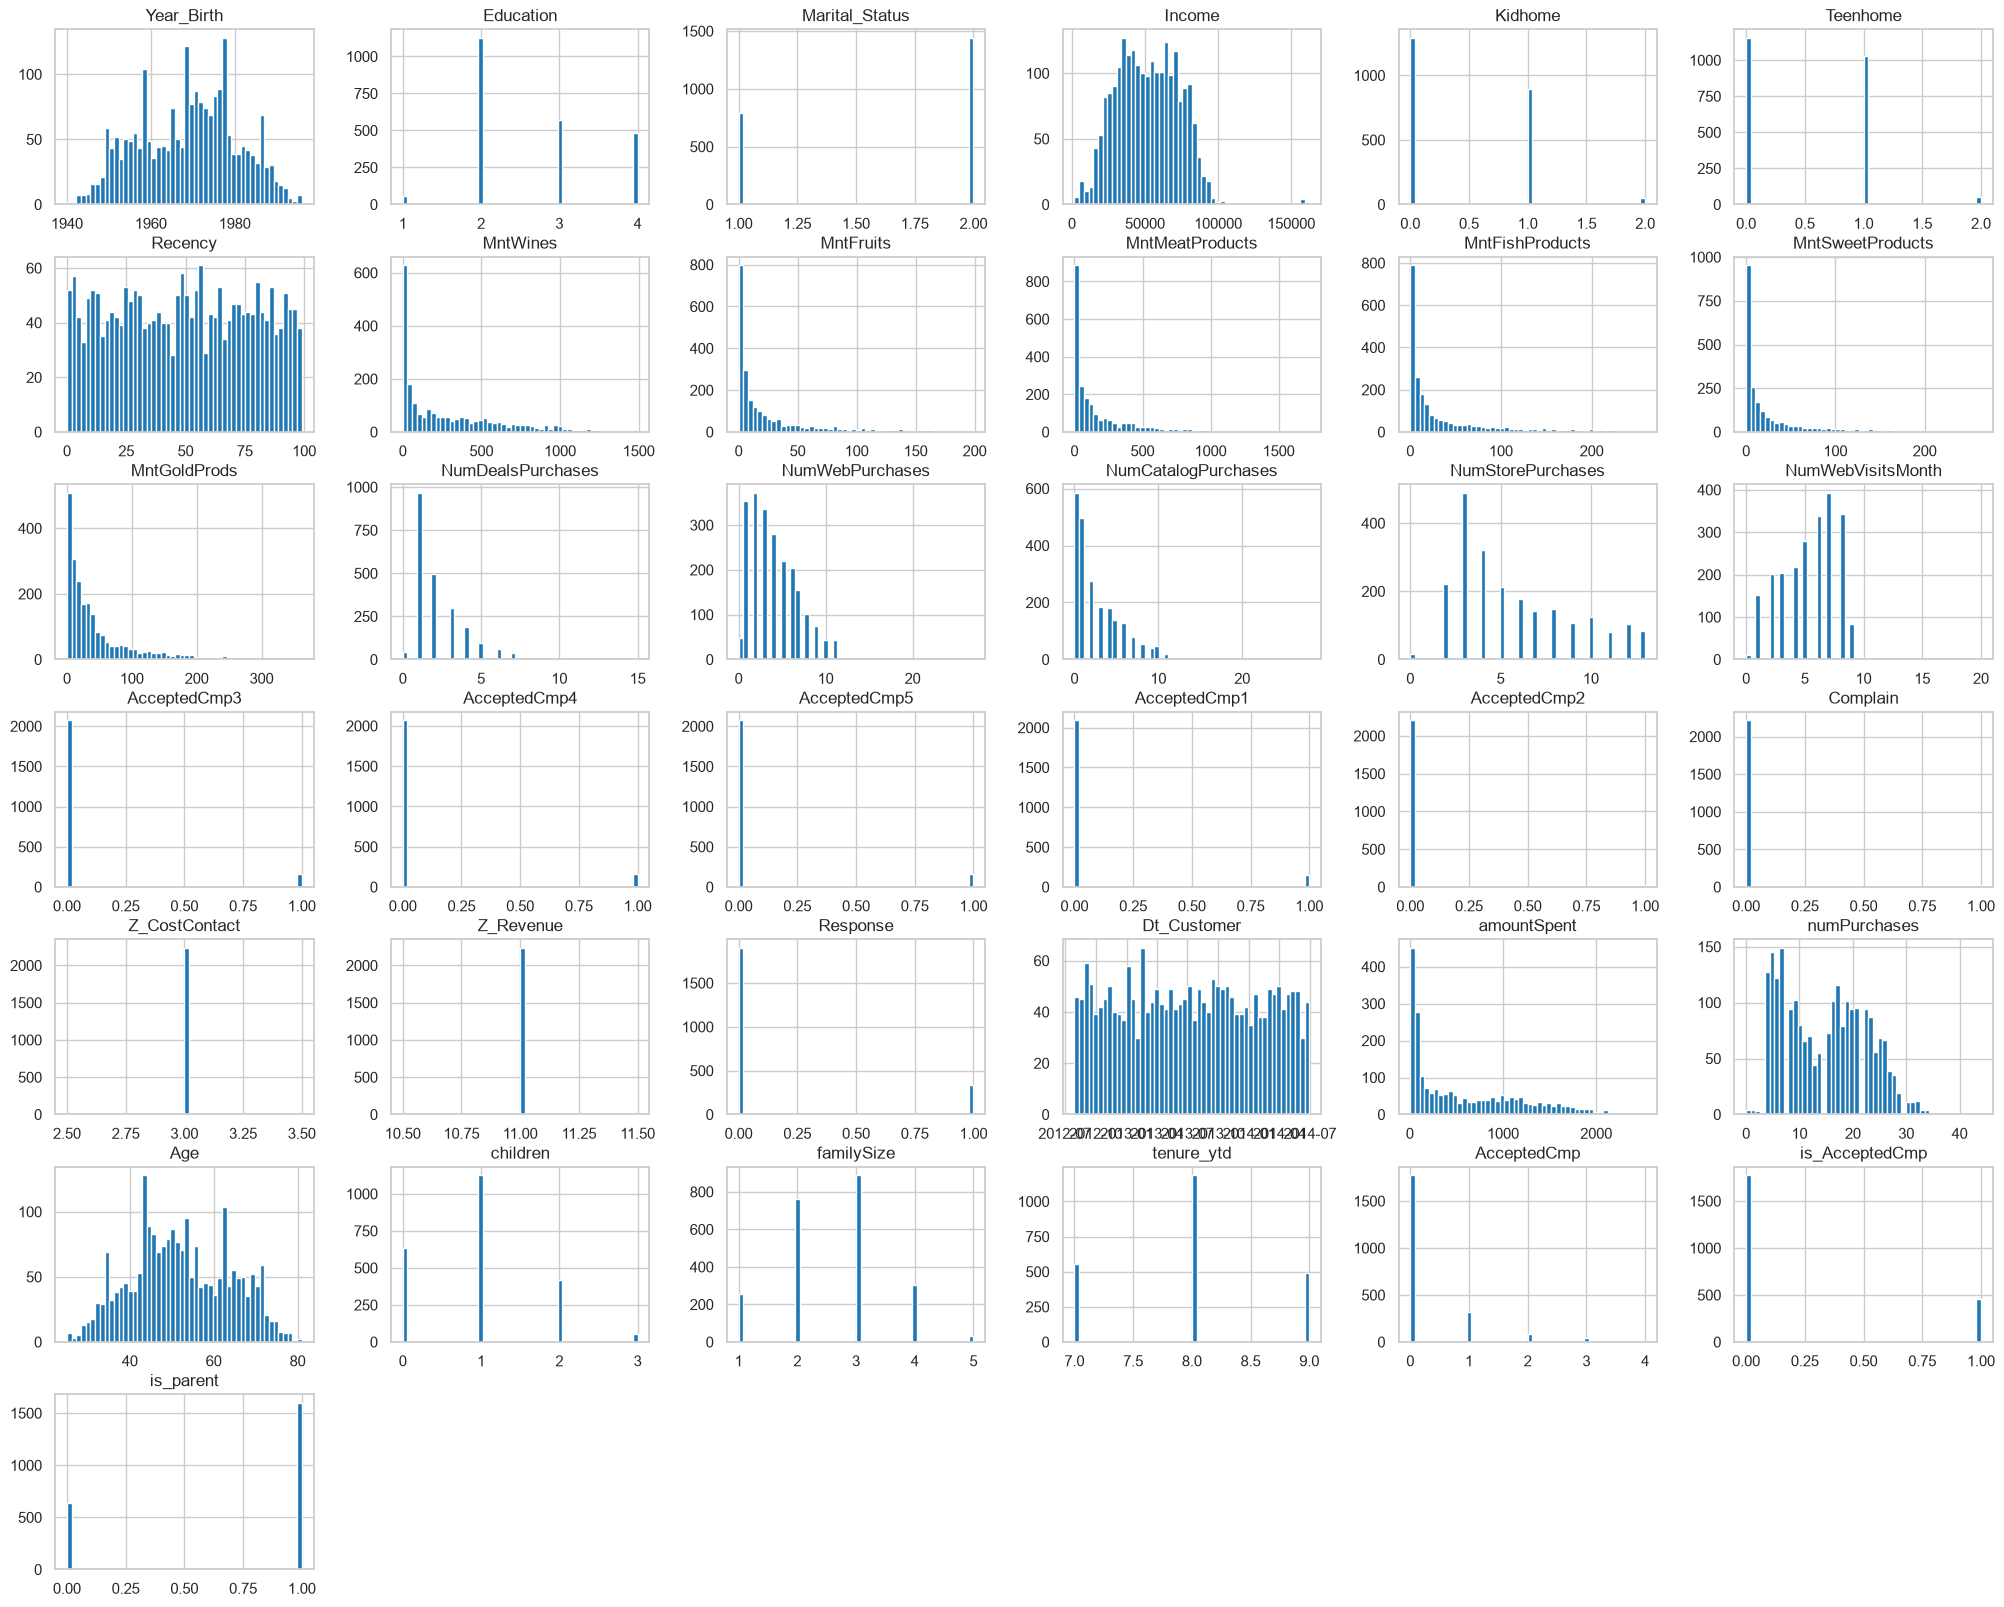

In [92]:
# check for numerical features after filtering
df.hist(bins=50,figsize=(25,20))
plt.show


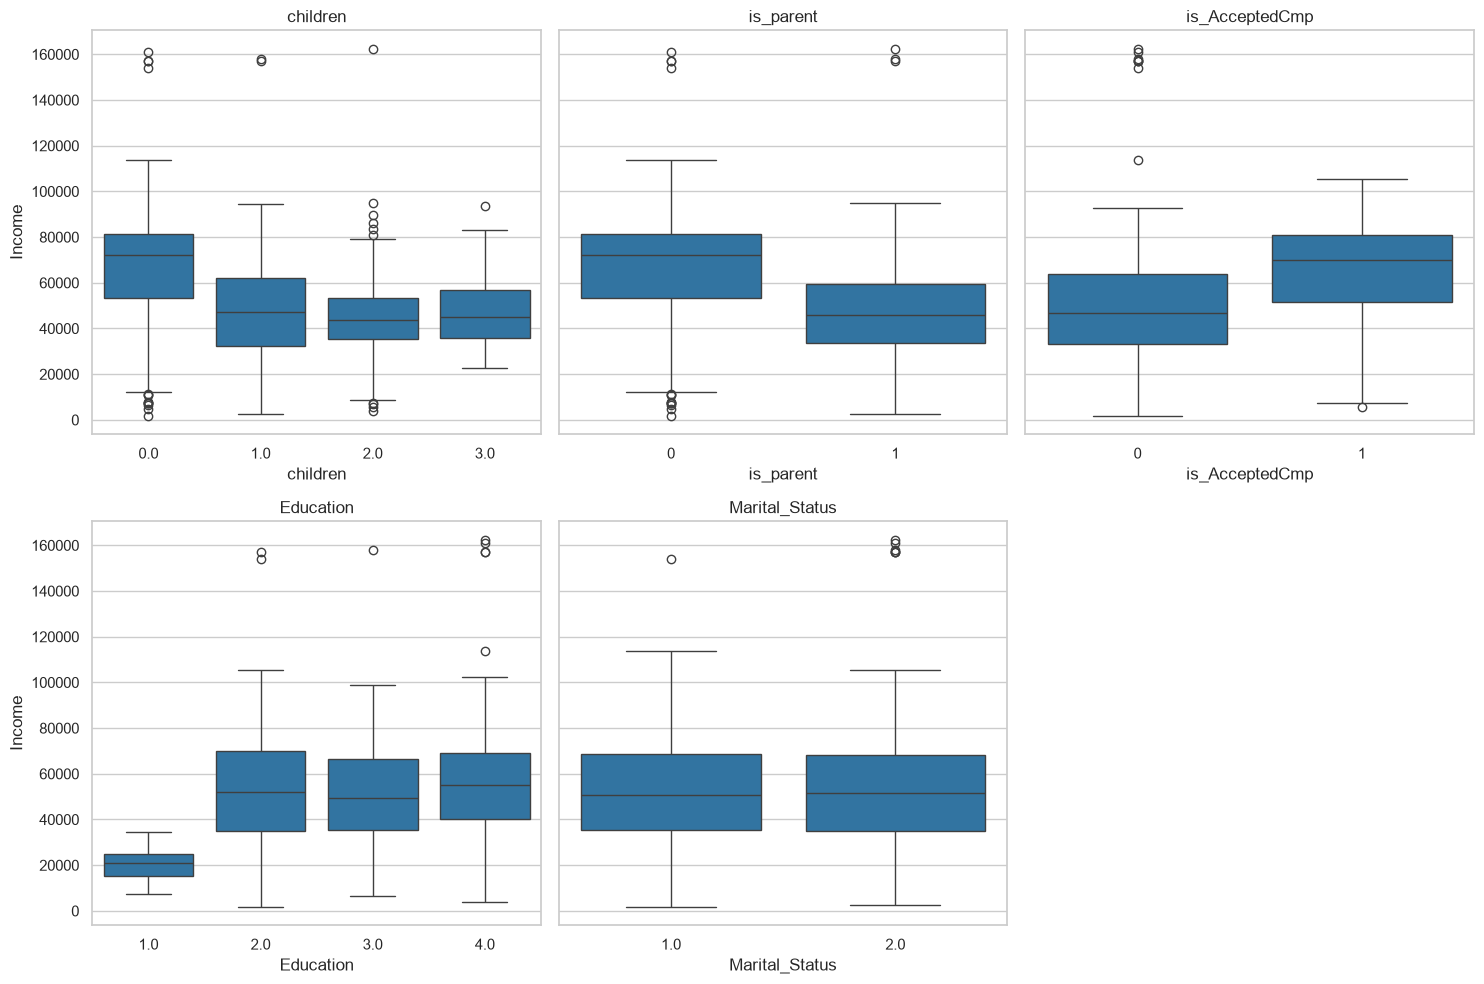

In [93]:
# boxplot for Income vs categorical features

# Define the features for boxplots
boxplot_features = ["children", "is_parent", "is_AcceptedCmp", 
                              "Education", "Marital_Status"]
fig, axes = plt.subplots(2, 3, figsize=(15, 10), sharey=True)
axes = axes.flatten()

# Create boxplots for each feature
for ax, col in zip(axes, boxplot_features):
    sns.boxplot(data=df, x=col, y="Income", ax=ax)
    ax.set_title(col)

# Hide the unused 6th subplot
for i in range(len(boxplot_features), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()


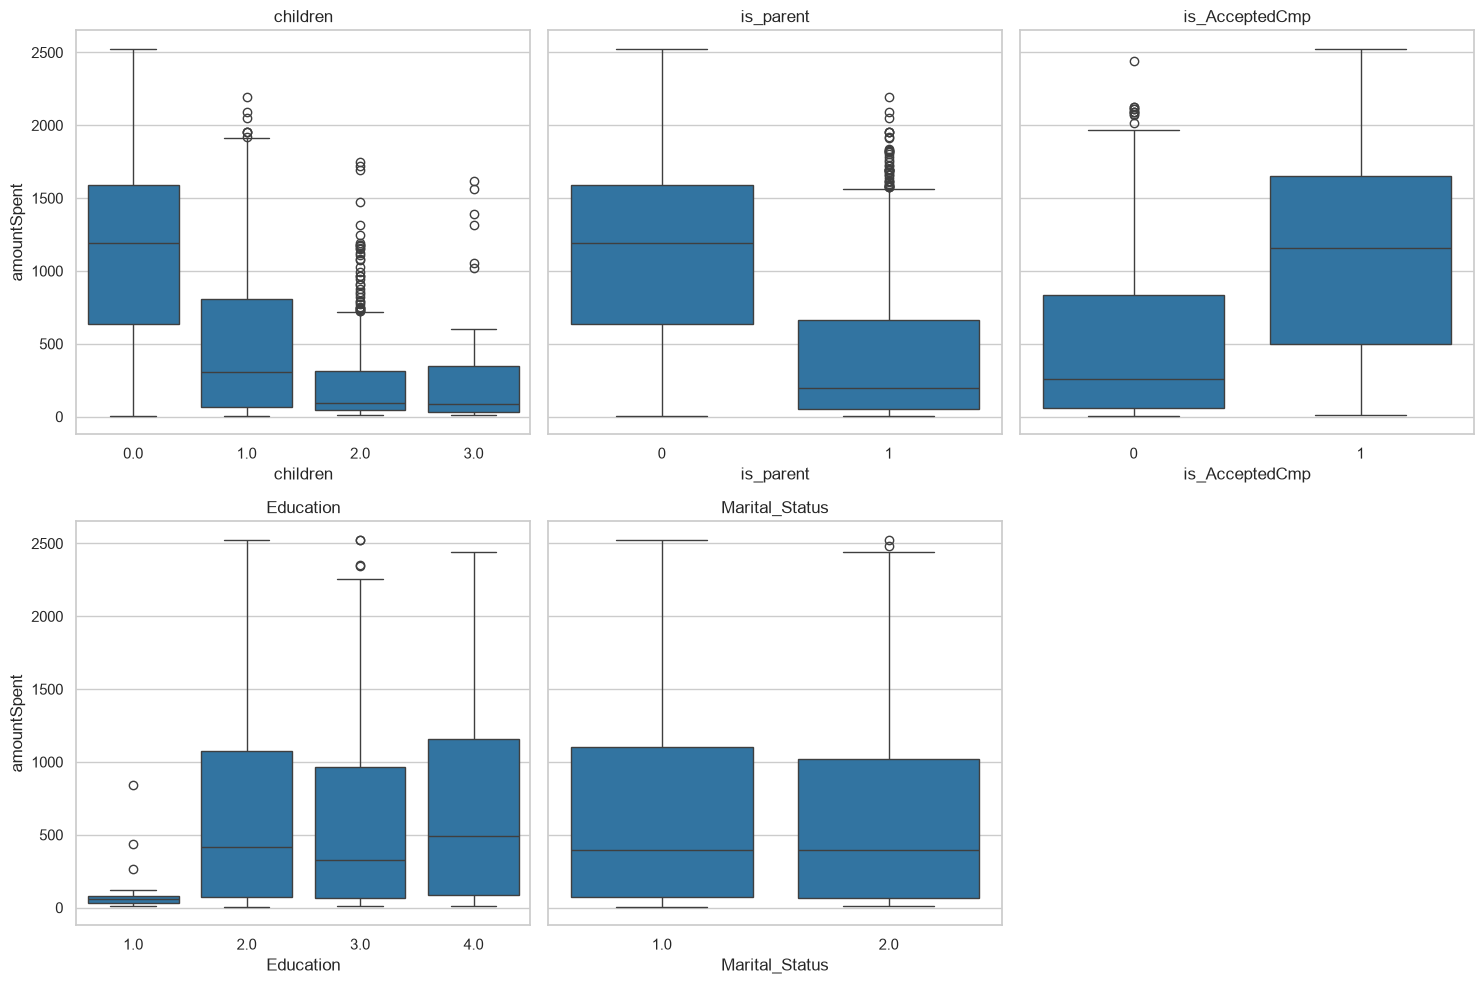

In [94]:

# boxplot for amountSpent vs categorical features
fig, axes = plt.subplots(2, 3, figsize=(15, 10), sharey=True)
axes = axes.flatten()

# Create boxplots for each feature
for ax, col in zip(axes, boxplot_features):
    sns.boxplot(data=df, x=col, y="amountSpent", ax=ax)
    ax.set_title(col)

# Hide the unused 6th subplot
for i in range(len(boxplot_features), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()


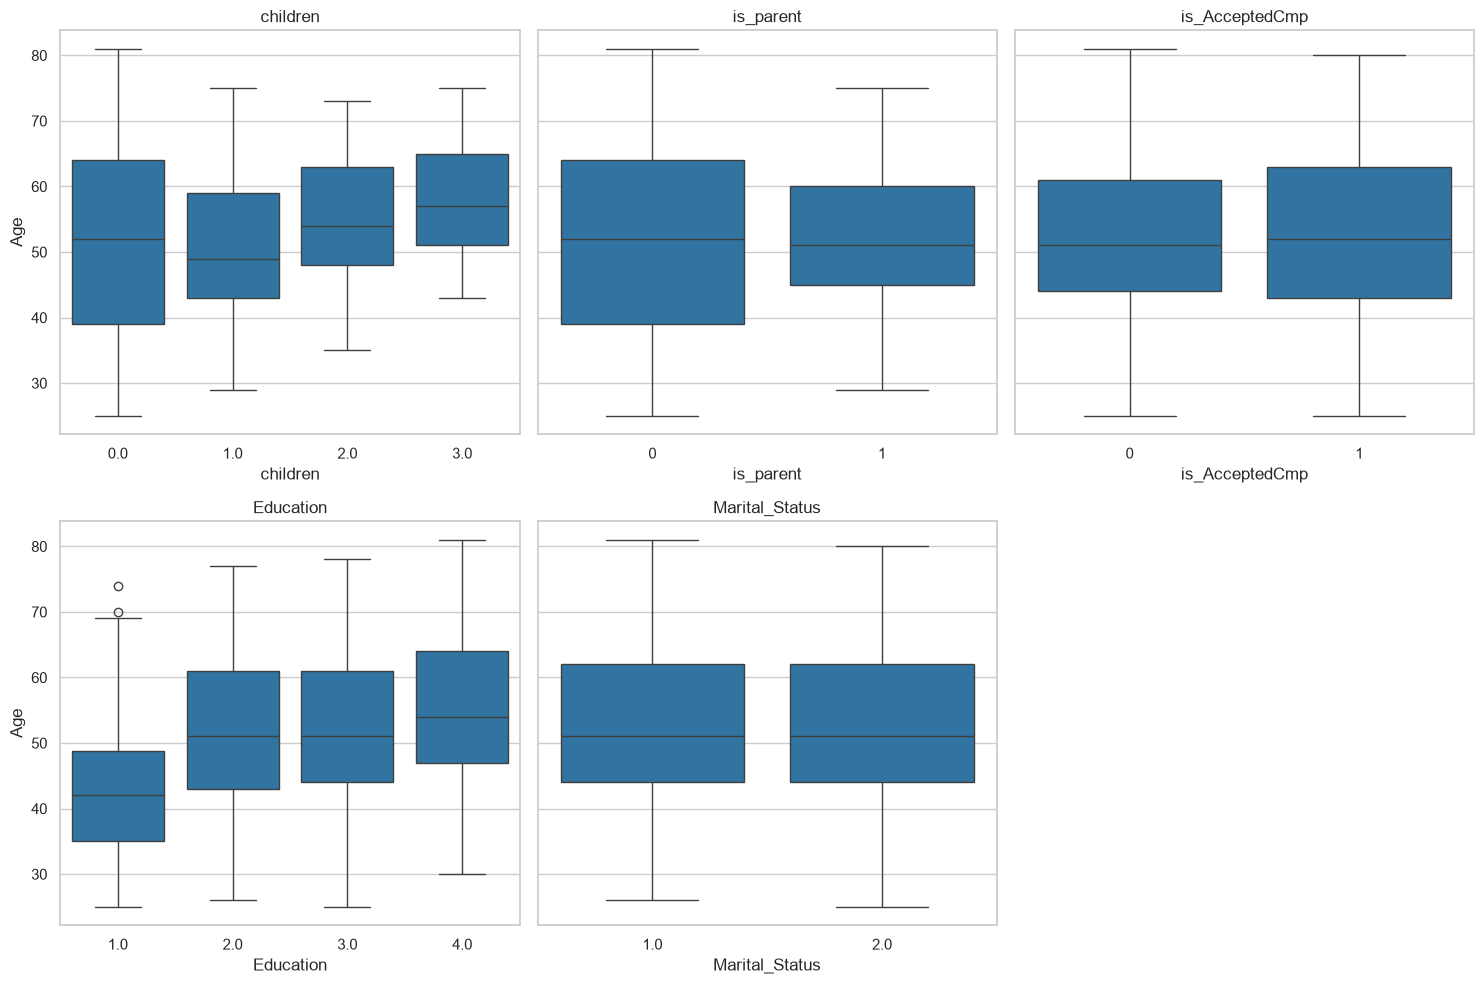

In [95]:
# boxplot for Age vs categorical features

# Define the features for boxplots
boxplot_features = ["children", "is_parent", "is_AcceptedCmp", 
                              "Education", "Marital_Status"]
fig, axes = plt.subplots(2, 3, figsize=(15, 10), sharey=True)
axes = axes.flatten()

# Create boxplots for each feature
for ax, col in zip(axes, boxplot_features):
    sns.boxplot(data=df, x=col, y="Age", ax=ax)
    ax.set_title(col)

# Hide the unused 6th subplot
for i in range(len(boxplot_features), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()


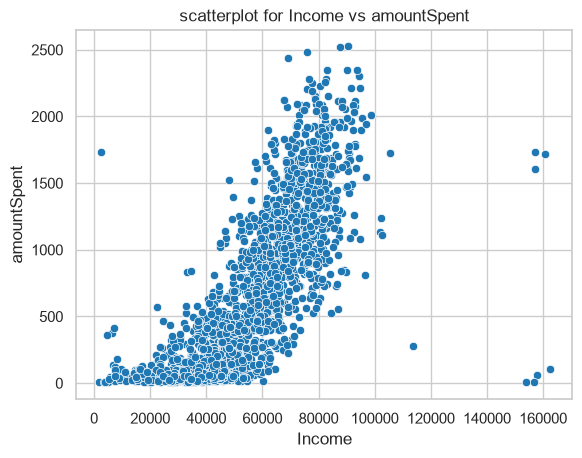

In [96]:
# scatterplot for Income vs amountSpent
sns.scatterplot(data=df, x="Income", y="amountSpent", palette="tab10")
plt.title("scatterplot for Income vs amountSpent")
plt.show()

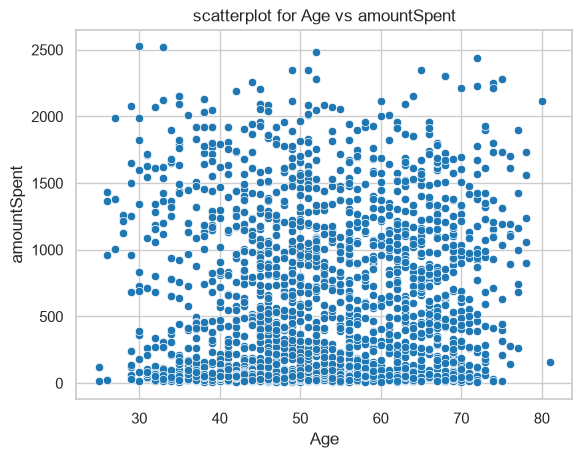

In [97]:
# scatterplot for Age vs amountSpent
sns.scatterplot(data=df, x="Age", y="amountSpent", palette="tab10")
plt.title("scatterplot for Age vs amountSpent")
plt.show()

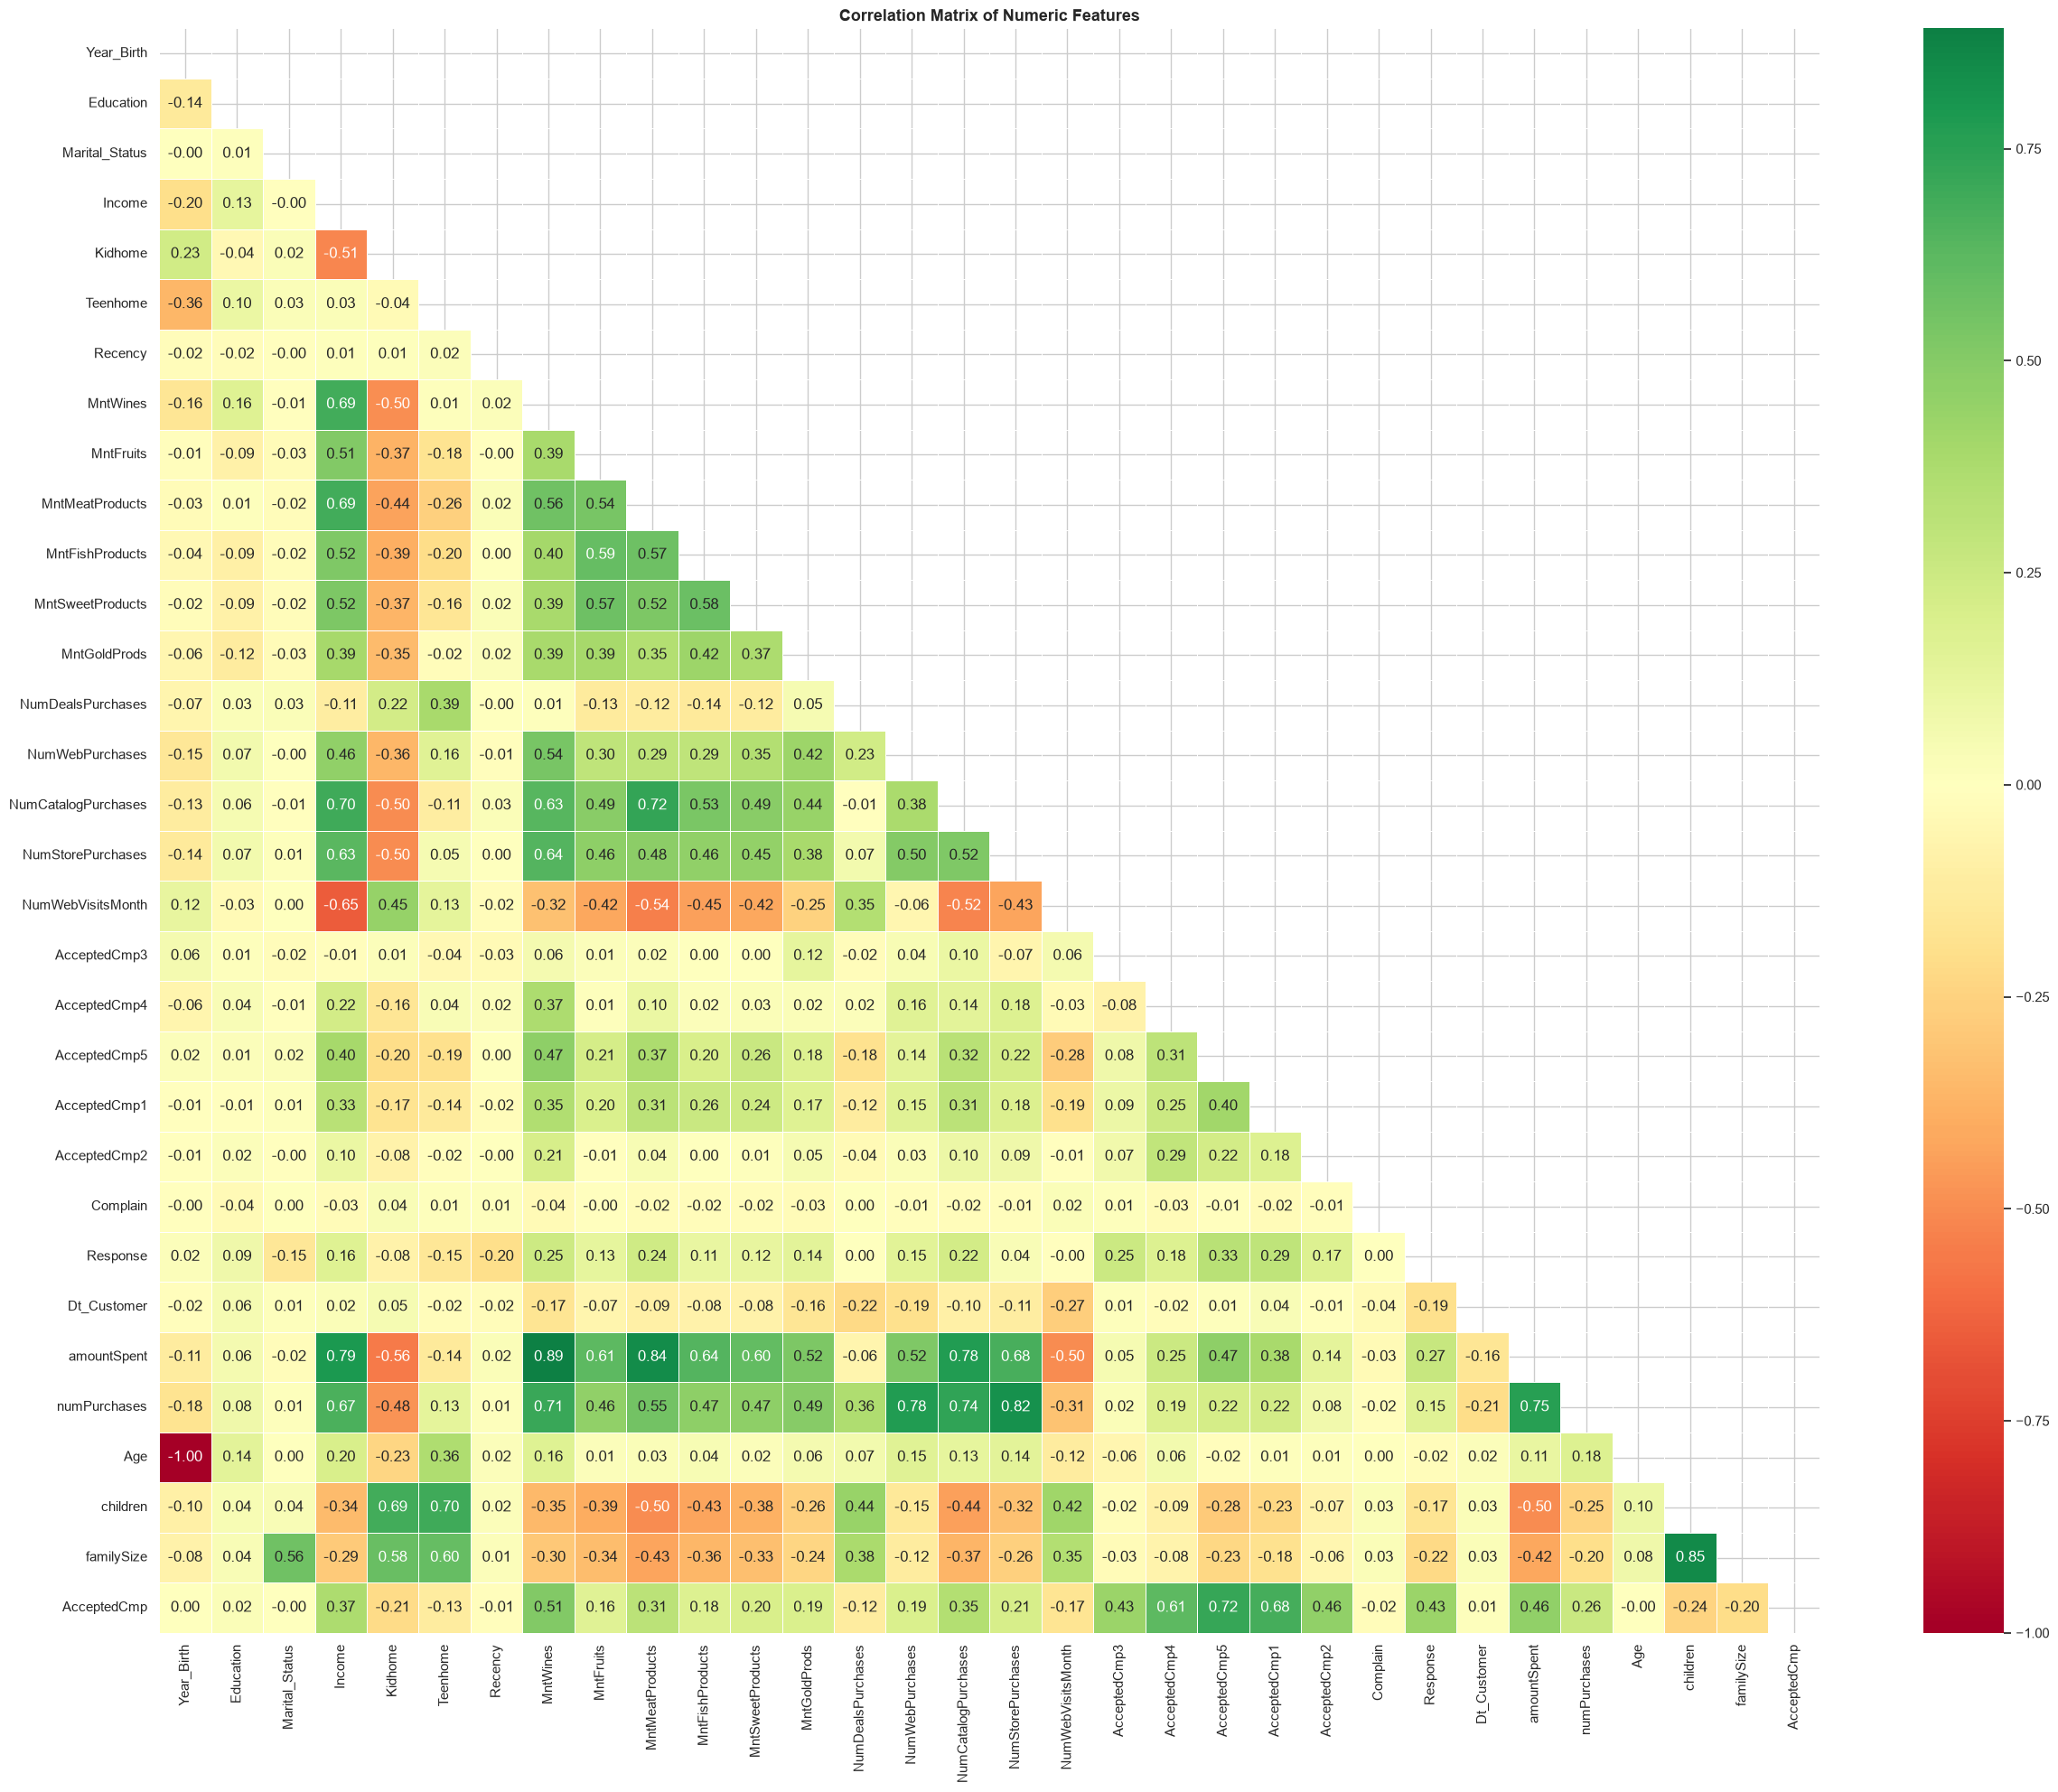

In [98]:
# correlation matrix for numeric features
numeric_cols = ['Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts',
       'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
       'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
       'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3',
       'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2',
       'Complain', 'Response', 'Dt_Customer',
       'amountSpent', 'numPurchases', 'Age', 'children', 'familySize',
       'AcceptedCmp']
cols = [c for c in numeric_cols if c in df.columns]
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(25, 20))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, linewidths=0.5, ax=ax)
ax.set_title('Correlation Matrix of Numeric Features', fontsize=13, fontweight='bold')
fig.tight_layout()
#plt.savefig('../reports/figures/04_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

In [99]:
# List all column names in the DataFrame
df.columns

Index(['Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts',
       'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
       'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
       'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3',
       'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2',
       'Complain', 'Z_CostContact', 'Z_Revenue', 'Response', 'Dt_Customer',
       'amountSpent', 'numPurchases', 'Age', 'children', 'familySize',
       'tenure_ytd', 'AcceptedCmp', 'is_AcceptedCmp', 'is_parent'],
      dtype='str')

## 4. Preprocessing Pipeline

In [100]:
# Define the columns for preprocessing

NUM_COLS = ['Education', 'Income','Recency', 'Kidhome', 'Teenhome',
             'children', 'familySize', 'is_parent', 'Marital_Status', 'Age']                                             

LOG_COLS = ['MntWines','MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
            'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 
            'amountSpent' , 'numPurchases'    
                ]

DROP_COLS = [
    "Year_Birth", 
     'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 
    'Z_CostContact', 'Z_Revenue', 'Dt_Customer', 'engage_days', 'is_AcceptedCmp', 
    'tenure_mnth', 'Complain', 'is_AcceptedCmp', 'Response',  'AcceptedCmp', 'tenure_ytd'
]


In [101]:
# Set the configuration to output pandas DataFrames from transformers
set_config(transform_output="pandas")

# preprocessing pipelines for numeric and log columns 

num_pipeline = Pipeline([             #small pipeline for numeric columns 
    ('standardize', StandardScaler()) #scale all numeric columns
])

def log_transformation(x):
    return np.log(x+1)

log_pipeline = Pipeline([           #small pipeline for log columns 
    ('log transform', FunctionTransformer(log_transformation, 
                                          feature_names_out='one-to-one')), #log transformation into the pipeline
    ('standardize', StandardScaler())     #scale all log columns
])

processing_pipeline = ColumnTransformer([    #transformer to merges the processed columns
    ('numeric', num_pipeline, NUM_COLS),     #numeric columns
    ('log', log_pipeline, LOG_COLS),         #log columns
  ])

# Fit and transform the data through the preprocessing steps
df_processed = processing_pipeline.fit_transform(df)


In [ ]:
# check the first few rows of the processed DataFrame
df_processed.head()

,numeric__Education,numeric__Income,numeric__Recency,numeric__Kidhome,numeric__Teenhome,numeric__children,numeric__familySize,numeric__is_parent,log__MntWines,log__MntFruits,...,log__MntFishProducts,log__MntSweetProducts,log__MntGoldProds,log__NumDealsPurchases,log__NumWebPurchases,log__NumCatalogPurchases,log__NumStorePurchases,log__NumWebVisitsMonth,log__amountSpent,log__numPurchases
0,-0.792105,0.288126,0.306856,-0.824939,-0.930615,-1.264308,-1.758810,-1.584362,0.987047,1.433415,...,1.579760,1.410558,1.062164,0.652625,1.280181,1.804684,-0.394879,0.706206,1.202519,1.128552
1,-0.792105,-0.260839,-0.383971,1.032627,0.905974,1.395139,0.445618,0.631169,-1.215042,-0.984619,...,-0.866121,-0.971131,-0.912916,0.042160,-1.396608,-0.405821,-1.445012,0.087735,-1.558363,-1.210009
2,-0.792105,0.915335,-0.798467,-0.824939,-0.930615,-1.264308,-0.656596,-1.584362,0.766070,1.066065,...,1.317483,0.533561,0.497123,-0.818241,1.280181,0.119936,1.225998,-0.304227,0.703320,0.830830
3,-0.792105,-1.177706,-0.798467,1.032627,-0.930615,0.065416,0.445618,0.631169,-1.215042,-0.400868,...,-0.082362,-0.536177,-1.032654,0.042160,-0.675007,-1.304608,-0.394879,0.419135,-1.111381,-0.762120
4,1.590069,0.295341,1.550344,1.032627,-0.930615,0.065416,0.445618,0.631169,0.268152,0.984625,...,0.793672,0.684891,-0.270788,1.513026,0.558579,0.492966,0.296827,0.087735,0.289489,0.660970


In [ ]:
# Add IDs back to the processed DataFrame, preserving their original order
df_processed.insert(0, "ID", customer_ids.loc[df.index].to_numpy())
df_processed.head()

,ID,numeric__Education,numeric__Income,numeric__Recency,numeric__Kidhome,numeric__Teenhome,numeric__children,numeric__familySize,numeric__is_parent,numeric__Marital_Status,...,log__MntFishProducts,log__MntSweetProducts,log__MntGoldProds,log__NumDealsPurchases,log__NumWebPurchases,log__NumCatalogPurchases,log__NumStorePurchases,log__NumWebVisitsMonth,log__amountSpent,log__numPurchases
0,5524,-0.792105,0.288126,0.306856,-0.824939,-0.930615,-1.264308,-1.758810,-1.584362,-1.347635,...,1.579760,1.410558,1.062164,0.652625,1.280181,1.804684,-0.394879,0.706206,1.202519,1.128552
1,2174,-0.792105,-0.260839,-0.383971,1.032627,0.905974,1.395139,0.445618,0.631169,-1.347635,...,-0.866121,-0.971131,-0.912916,0.042160,-1.396608,-0.405821,-1.445012,0.087735,-1.558363,-1.210009
2,4141,-0.792105,0.915335,-0.798467,-0.824939,-0.930615,-1.264308,-0.656596,-1.584362,0.742041,...,1.317483,0.533561,0.497123,-0.818241,1.280181,0.119936,1.225998,-0.304227,0.703320,0.830830
3,6182,-0.792105,-1.177706,-0.798467,1.032627,-0.930615,0.065416,0.445618,0.631169,0.742041,...,-0.082362,-0.536177,-1.032654,0.042160,-0.675007,-1.304608,-0.394879,0.419135,-1.111381,-0.762120
4,5324,1.590069,0.295341,1.550344,1.032627,-0.930615,0.065416,0.445618,0.631169,0.742041,...,0.793672,0.684891,-0.270788,1.513026,0.558579,0.492966,0.296827,0.087735,0.289489,0.660970


In [ ]:
# save the processed DataFrame to a CSV file
PROCESSED_PATH = '../data/processed/customer_segmentation_processed.csv'
os.makedirs(os.path.dirname(PROCESSED_PATH), exist_ok=True)
df_processed.to_csv(PROCESSED_PATH, index=False)

print(f"Processed dataset saved with {df_processed.shape[1]} columns.")

Processed dataset saved with 24 columns.
